# Extrapolation lab — is "no extrapolation" a property of trees or of ensembles?

This notebook is the code behind [section 13.1 of the README](../README.md#131-extrapolation-with-members-that-are-not-trees-disadvantage-4).

[Disadvantage 4](../README.md#disadvantage-4) says tree ensembles cannot extrapolate: past the largest
training value they repeat their last leaf. The question here is whether that comes from the **trees** or from
the **ensemble**. What if every member — the base learner in bagging, every sequential learner in boosting — is
a different kind of model, for example a small neural network?

| Part | Question |
|---|---|
| A | How do tree ensembles behave past the training range, and which fixes carry a trend? |
| B | What happens when the members are not trees (linear, neural nets, polynomials, splines, k-NN, SVR)? |
| C | Are the neural-net ensembles reliable, or does the answer depend on the random seed? |
| D | Does the answer depend on the curve? The same experiment on a curve that keeps returning to zero |

**Setup.** 300 points from $y = 2x + 3\sin(x)$ plus Gaussian noise (σ = 1), trained on $x \in [0, 10]$ and
tested on $x \in [10, 15]$, where no training point exists.

**Running it.** Needs `numpy`, `scikit-learn`, `matplotlib`, `xgboost` and `lightgbm` (see `requirements.txt`).
On macOS, xgboost and LightGBM need the OpenMP runtime (`brew install libomp`). A full run takes a few minutes,
mostly the neural networks in parts B and C.

In [1]:
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import xgboost as xgb
from sklearn.base import clone
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, SplineTransformer, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # small nets stop at max_iter; that is fine here
warnings.filterwarnings("ignore", message=".*gblinear.* is deprecated")   # still works in xgboost 3.4; see part A
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

SEED = 0
N_TRAIN = 300
NOISE_SD = 1.0
X_MIN, X_EDGE, X_FAR = 0.0, 10.0, 15.0   # train on [X_MIN, X_EDGE], test on [X_EDGE, X_FAR]

## The data

A rising trend ($2x$) with a wave on top ($3\sin x$). Inside the training range a flexible model can follow
both; past $x = 10$ a model only gets the trend right if its shape *carries* a trend.

In [2]:
def true_pattern(x):
    return 2 * x + 3 * np.sin(x)


rng = np.random.default_rng(SEED)
x_tr = rng.uniform(X_MIN, X_EDGE, N_TRAIN)
y_tr = true_pattern(x_tr) + rng.normal(0, NOISE_SD, N_TRAIN)
x_te = np.linspace(X_EDGE, X_FAR, 200)
y_te = true_pattern(x_te)
X_tr, X_te = x_tr[:, None], x_te[:, None]
x_plot = np.linspace(X_MIN, X_FAR, 600)
X_plot = x_plot[:, None]
X_POINTS = np.array([[10.5], [15.0]])   # the two points every table reports
x_in = np.linspace(X_MIN, X_EDGE, 300)  # inside the training range, to check the fit there too
X_in = x_in[:, None]

print(f"training targets range from {y_tr.min():.1f} to {y_tr.max():.1f}")
print(f"truth: f(10.5) = {true_pattern(10.5):.1f}, f(15) = {true_pattern(15):.1f}")

training targets range from -0.4 to 20.8
truth: f(10.5) = 18.4, f(15) = 32.0


Three helpers used by every part:

* `score` — the prediction at $x = 10.5$ and $x = 15$, the RMSE over the test range $[10, 15]$, and the RMSE
  against the true pattern **inside** the training range $[0, 10]$ (a model can extrapolate well simply because
  it is too simple to follow the wave — this column catches that);
* `gradient_boost` — squared-loss gradient boosting with **any** regressor as the member: each round fits
  the current residuals and adds a shrunken copy of the fit. scikit-learn's `GradientBoostingRegressor` only
  accepts trees, so we write the loop ourselves;
* `draw_background` — training points, the true pattern, and a grey band over the test range.

In [3]:
def score(predict):
    at_10_5, at_15 = predict(X_POINTS)
    rmse_test = np.sqrt(np.mean((predict(X_te) - y_te) ** 2))
    rmse_inside = np.sqrt(np.mean((predict(X_in) - true_pattern(x_in)) ** 2))
    return at_10_5, at_15, rmse_test, rmse_inside


def gradient_boost(base, X, y, rounds, learning_rate):
    """Fit `rounds` copies of `base`, each to the residuals of the sum so far; return the sum's predict."""
    start = y.mean()
    members, fitted = [], np.full(len(y), start)
    for _ in range(rounds):
        member = clone(base).fit(X, y - fitted)
        members.append(member)
        fitted += learning_rate * member.predict(X)
    return lambda X_new: start + learning_rate * sum(m.predict(X_new) for m in members)


def draw_background(ax):
    ax.axvspan(X_EDGE, X_FAR, color="0.9", zorder=0)
    ax.scatter(x_tr, y_tr, s=4, color="0.6", zorder=1)
    ax.plot(x_plot, true_pattern(x_plot), "k--", lw=1.5, label="true pattern", zorder=4)
    ax.set_xlabel("x")

---
## Part A · Tree ensembles, and three ways to give them a trend

**Goal:** show that tree depth does not matter past the edge, and compare three ways of adding a trend:

* xgboost with **linear members** (`booster="gblinear"`) instead of trees;
* gradient boosting that **starts from a linear model** (`init=LinearRegression()`) and lets trees fit what is
  left;
* xgboost trees added on top of a linear model's prediction (`base_margin`), the same idea in xgboost;
* LightGBM with a **linear model inside each leaf** (`linear_tree=True`).

In [4]:
linear = LinearRegression().fit(X_tr, y_tr)
on_linear_margin = xgb.XGBRegressor(n_estimators=300, max_depth=6).fit(X_tr, y_tr, base_margin=linear.predict(X_tr))

TREE_ENSEMBLES = {
    "random forest": RandomForestRegressor(n_estimators=300, random_state=SEED).fit(X_tr, y_tr).predict,
    **{f"gradient boosting, depth {d}": GradientBoostingRegressor(n_estimators=300, max_depth=d, random_state=SEED)
       .fit(X_tr, y_tr).predict for d in (1, 3, 8)},
    "xgboost, depth 6": xgb.XGBRegressor(n_estimators=300, max_depth=6).fit(X_tr, y_tr).predict,
    "LightGBM, constant leaves": lgb.LGBMRegressor(n_estimators=300, verbose=-1).fit(X_tr, y_tr).predict,
    "xgboost, linear members (gblinear)": xgb.XGBRegressor(booster="gblinear", n_estimators=300).fit(X_tr, y_tr).predict,
    "one linear regression (reference)": linear.predict,
    "gradient boosting from a linear start": GradientBoostingRegressor(
        n_estimators=300, max_depth=3, init=LinearRegression(), random_state=SEED).fit(X_tr, y_tr).predict,
    "xgboost on a linear base_margin": lambda X: on_linear_margin.predict(X, base_margin=linear.predict(X)),
    "LightGBM, linear leaves": lgb.LGBMRegressor(n_estimators=300, linear_tree=True, verbose=-1).fit(X_tr, y_tr).predict,
}

print(f"{'model':<40} {'at 10.5':>8} {'at 15':>7} {'RMSE test':>10} {'RMSE inside':>12}")
for name, predict in TREE_ENSEMBLES.items():
    at_10_5, at_15, rmse_test, rmse_inside = score(predict)
    print(f"{name:<40} {at_10_5:8.1f} {at_15:7.1f} {rmse_test:10.1f} {rmse_inside:12.2f}")
print(f"{'truth':<40} {true_pattern(10.5):8.1f} {true_pattern(15):7.1f}")

model                                     at 10.5   at 15  RMSE test  RMSE inside
random forest                                18.2    18.2        8.5         0.66
gradient boosting, depth 1                   18.3    18.3        8.4         0.35
gradient boosting, depth 3                   17.9    17.9        8.7         0.64
gradient boosting, depth 8                   17.8    17.8        8.8         0.95
xgboost, depth 6                             18.5    18.5        8.3         0.95
LightGBM, constant leaves                    18.4    18.4        8.3         0.49
xgboost, linear members (gblinear)           21.3    30.2        2.4         1.99
one linear regression (reference)            21.3    30.2        2.4         1.99
gradient boosting from a linear start        19.0    27.8        3.1         0.65
xgboost on a linear base_margin              19.5    28.4        2.8         0.95
LightGBM, linear leaves                      17.6    12.9       11.5         0.43
truth           

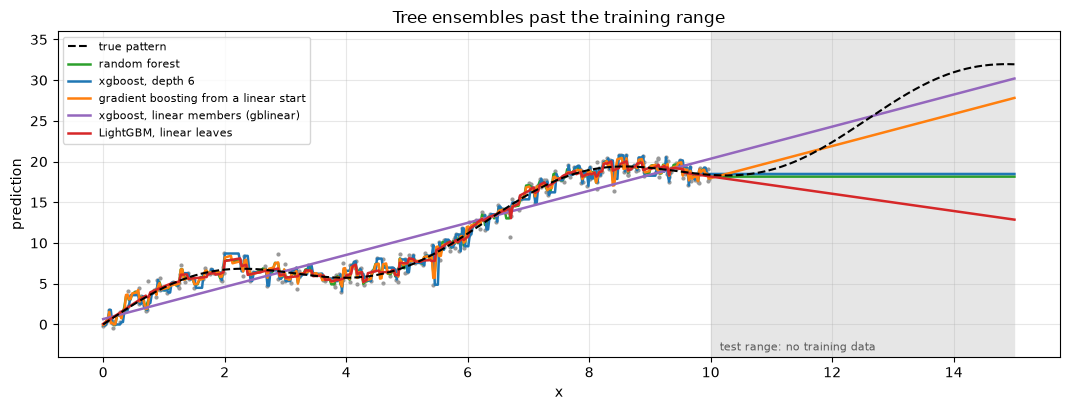

In [5]:
SHOWN = {"random forest": "tab:green", "xgboost, depth 6": "tab:blue",
         "gradient boosting from a linear start": "tab:orange", "xgboost, linear members (gblinear)": "tab:purple",
         "LightGBM, linear leaves": "tab:red"}

fig, ax = plt.subplots(figsize=(10.8, 4.2))
draw_background(ax)
for name, color in SHOWN.items():
    ax.plot(x_plot, TREE_ENSEMBLES[name](X_plot), color=color, lw=1.8, label=name, zorder=3)
ax.text(X_EDGE + 0.15, -3.2, "test range: no training data", fontsize=8, color="0.35")
ax.set(ylabel="prediction", ylim=(-4, 36), title="Tree ensembles past the training range")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Depth changes nothing.** Every tree-only ensemble predicts the same number at $x = 10.5$ and at $x = 15$
>   (17.8–18.5, truth 18.4 and 32.0): past its last split every tree repeats its last leaf, so any sum or
>   average of trees is flat there. Inside the training range they fit well (RMSE inside 0.35–0.95).
> * **Linear members give a linear model.** xgboost with `gblinear` predicts *exactly* what one linear
>   regression predicts (30.2 at $x = 15$). It carries the trend but cannot follow the wave inside the range
>   (RMSE inside 1.99, the worst in the table). xgboost 3.4 marks `gblinear` as deprecated.
> * **A linear start plus trees gets both.** Starting from a linear model (`init=LinearRegression()`) or adding
>   trees on top of one (`base_margin`) fits the wave inside (0.65, 0.95) and keeps rising outside (27.8, 28.4).
>   Past the edge the trees only add a constant, so the wave is lost but the trend continues.
> * **Linear leaves can be worse than flat.** LightGBM's linear leaves fit well inside (0.43) but drop to 12.9:
>   the last leaf's straight line continues the *local* downward slope of the wave just before $x = 10$
>   (RMSE 11.5 against 8.3 for constant leaves).

### Part A, continued · Is xgboost's `gblinear` just a linear regression?

In the plot above the `gblinear` line lies exactly on a straight line. That is no accident: boosting adds up
its members, a sum of straight lines is a straight line, so xgboost with linear members can only ever end up
as **one linear model**. Which one? We fit plain linear models on the same training data and compare:

| Penalty | scikit-learn | xgboost `gblinear` |
|---|---|---|
| none | `LinearRegression()` | default (`reg_lambda=0`, `reg_alpha=0`) |
| L2 (ridge) | `Ridge(alpha=λ·n)` | `reg_lambda=λ` |
| L1 (lasso) | `Lasso(alpha=α)` | `reg_alpha=α` |

The two libraries scale the penalty differently: xgboost multiplies `reg_lambda` by the number of training
rows *n*, while scikit-learn's `Ridge` does not (hence `alpha = λ·n`); scikit-learn's `Lasso` divides the
squared error by *n*, which cancels the same factor (hence `alpha = α`). λ = α = 1 is strong enough to shrink
the slope visibly with one feature and 300 rows.

In [6]:
N = len(y_tr)
LAMBDA, ALPHA = 1.0, 1.0                                          # <- try changing this

LINEAR_PAIRS = {   # penalty -> (scikit-learn model, xgboost gblinear model), both fitted on the same data
    "none": (LinearRegression(), xgb.XGBRegressor(booster="gblinear", n_estimators=300)),
    "L2 (ridge)": (Ridge(alpha=LAMBDA * N), xgb.XGBRegressor(booster="gblinear", n_estimators=300, reg_lambda=LAMBDA)),
    "L1 (lasso)": (Lasso(alpha=ALPHA), xgb.XGBRegressor(booster="gblinear", n_estimators=300, reg_alpha=ALPHA)),
}
fitted_pairs = {penalty: (sk.fit(X_tr, y_tr).predict, xg.fit(X_tr, y_tr).predict)
                for penalty, (sk, xg) in LINEAR_PAIRS.items()}


def slope_and_intercept(predict):
    at_0, at_1 = predict(np.array([[0.0], [1.0]]))
    return at_1 - at_0, at_0


print(f"{'penalty':<11} {'library':<13} {'slope':>6} {'intercept':>10} {'at 15':>6} {'RMSE test':>10} {'RMSE inside':>12}")
for penalty, predicts in fitted_pairs.items():
    for library, predict in zip(("scikit-learn", "gblinear"), predicts):
        slope, intercept = slope_and_intercept(predict)
        _, at_15, rmse_test, rmse_inside = score(predict)
        print(f"{penalty:<11} {library:<13} {slope:6.3f} {intercept:10.3f} {at_15:6.1f} {rmse_test:10.1f} {rmse_inside:12.2f}")
    gap = np.abs(predicts[0](X_plot) - predicts[1](X_plot)).max()
    print(f"{'':<11} largest gap between the two over [0, 15]: {gap:.1e}")

penalty     library        slope  intercept  at 15  RMSE test  RMSE inside
none        scikit-learn   1.970      0.655   30.2        2.4         1.99
none        gblinear       1.970      0.655   30.2        2.4         1.99
            largest gap between the two over [0, 15]: 6.3e-06
L2 (ridge)  scikit-learn   1.770      1.735   28.3        2.8         2.06
L2 (ridge)  gblinear       1.770      1.735   28.3        2.8         2.06
            largest gap between the two over [0, 15]: 5.8e-06
L1 (lasso)  scikit-learn   1.857      1.265   29.1        2.6         2.01
L1 (lasso)  gblinear       1.857      1.265   29.1        2.6         2.01
            largest gap between the two over [0, 15]: 6.1e-06


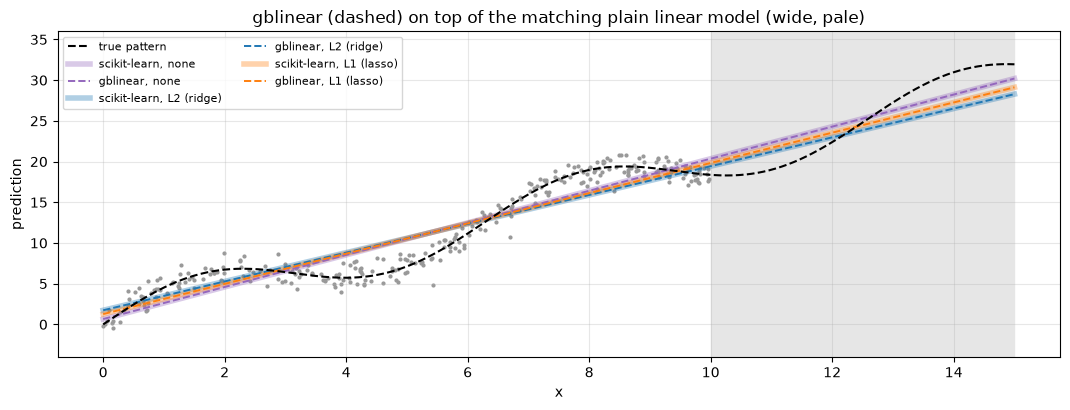

In [7]:
COLORS = {"none": "tab:purple", "L2 (ridge)": "tab:blue", "L1 (lasso)": "tab:orange"}

fig, ax = plt.subplots(figsize=(10.8, 4.2))
draw_background(ax)
for penalty, (sk_predict, xg_predict) in fitted_pairs.items():
    ax.plot(x_plot, sk_predict(X_plot), color=COLORS[penalty], lw=4, alpha=0.35, label=f"scikit-learn, {penalty}", zorder=2)
    ax.plot(x_plot, xg_predict(X_plot), color=COLORS[penalty], lw=1.4, ls="--", label=f"gblinear, {penalty}", zorder=3)
ax.set(ylabel="prediction", ylim=(-4, 36), title="gblinear (dashed) on top of the matching plain linear model (wide, pale)")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

> **How to read this**
> * **`gblinear` is a plain linear model, nothing more.** For every penalty its slope and intercept match
>   scikit-learn's to three decimals, and the two lines never differ by more than 6.3e-06 anywhere on
>   $[0, 15]$ — float32 rounding. No penalty gives `LinearRegression` (slope 1.970, 30.2 at $x = 15$); L2 gives
>   `Ridge` (1.770, 28.3); L1 gives `Lasso` (1.857, 29.1).
> * **Penalties shrink the slope, so they extrapolate *less*.** Here the trend is real, so shrinking it costs a
>   little both outside (test RMSE 2.4 → 2.8 for L2) and inside (1.99 → 2.06). With one feature and 300 rows
>   there is no over-fitting for a penalty to cure.
> * So "xgboost with linear members" is not a new kind of model: it is linear regression fitted by coordinate
>   descent. If a linear model is what you want, `LinearRegression`, `Ridge` or `Lasso` give the same answer
>   directly.

---
## Part B · Members that are not trees, boosted and bagged

**Goal:** swap the trees for other kinds of model and see whether the ensemble now extrapolates. Each member
is boosted (100 rounds, learning rate 0.1, with `gradient_boost` above) and bagged (50 bootstrap copies with
`BaggingRegressor`).

| Member | What it does past the edge of its data, on its own |
|---|---|
| linear regression | continues one global straight line |
| neural net with ReLU units | continues its last straight piece |
| neural net with tanh units | levels off once its units saturate |
| cubic polynomial | shoots off in the direction of its top coefficient |
| spline, continued as a straight line | continues the slope it has at the edge |
| spline, held constant | stays flat |
| k-nearest neighbours | repeats the nearest edge points (flat) |
| support vector regression, RBF kernel | falls back to its intercept far from the data |

In [8]:
def small_net(activation, seed, max_iter):
    return MLPRegressor(hidden_layer_sizes=(16,), activation=activation, max_iter=max_iter, random_state=seed)


MEMBERS = {
    "linear regression": LinearRegression(),
    "neural net, ReLU": small_net("relu", SEED, max_iter=500),
    "neural net, tanh": small_net("tanh", SEED, max_iter=500),
    "cubic polynomial": make_pipeline(PolynomialFeatures(3), StandardScaler(), Ridge(1.0)),
    "spline, straight-line ends": make_pipeline(SplineTransformer(n_knots=6, extrapolation="linear"), Ridge(1.0)),
    "spline, constant ends": make_pipeline(SplineTransformer(n_knots=6, extrapolation="constant"), Ridge(1.0)),
    "k-nearest neighbours, k=10": KNeighborsRegressor(n_neighbors=10),
    "SVR, RBF kernel": SVR(C=10),
}

boosted = {name: gradient_boost(member, X_tr, y_tr, rounds=100, learning_rate=0.1) for name, member in MEMBERS.items()}
bagged = {name: BaggingRegressor(estimator=member, n_estimators=50, random_state=SEED).fit(X_tr, y_tr).predict
          for name, member in MEMBERS.items()}

print(f"{'member':<28}|{'boosted':^32}|{'bagged':^32}")
print(f"{'':<28}|" + f"{'at 10.5':>8}{'at 15':>8}{'test':>8}{'inside':>8}|" * 2)
for name in MEMBERS:
    row = "".join("{:8.1f}{:8.1f}{:8.1f}{:8.2f}|".format(*score(predict[name])) for predict in (boosted, bagged))
    print(f"{name:<28}|{row}")
print(f"{'truth':<28}|{true_pattern(10.5):8.1f}{true_pattern(15):8.1f}")

member                      |            boosted             |             bagged             
                            | at 10.5   at 15    test  inside| at 10.5   at 15    test  inside|
linear regression           |    21.3    30.2     2.4    1.99|    21.3    30.2     2.4    1.99|
neural net, ReLU            |    21.1    26.7     3.6    0.97|    20.5    28.4     2.8    2.06|
neural net, tanh            |    21.8    25.5     4.1    1.19|    13.3    13.4    12.6    3.71|
cubic polynomial            |    20.6     9.7    10.8    1.74|    22.6    32.3     3.0    1.77|


spline, straight-line ends  |    17.0     8.3    14.2    0.21|    16.4     5.8    15.8    0.47|
spline, constant ends       |    18.0    18.0     8.6    0.21|    17.6    17.6     8.9    0.47|
k-nearest neighbours, k=10  |    18.0    18.0     8.6    1.86|    18.4    18.4     8.3    0.27|


SVR, RBF kernel             |    17.4     7.7    15.2    0.16|    17.2     9.5    14.0    0.18|
truth                       |    18.4    32.0


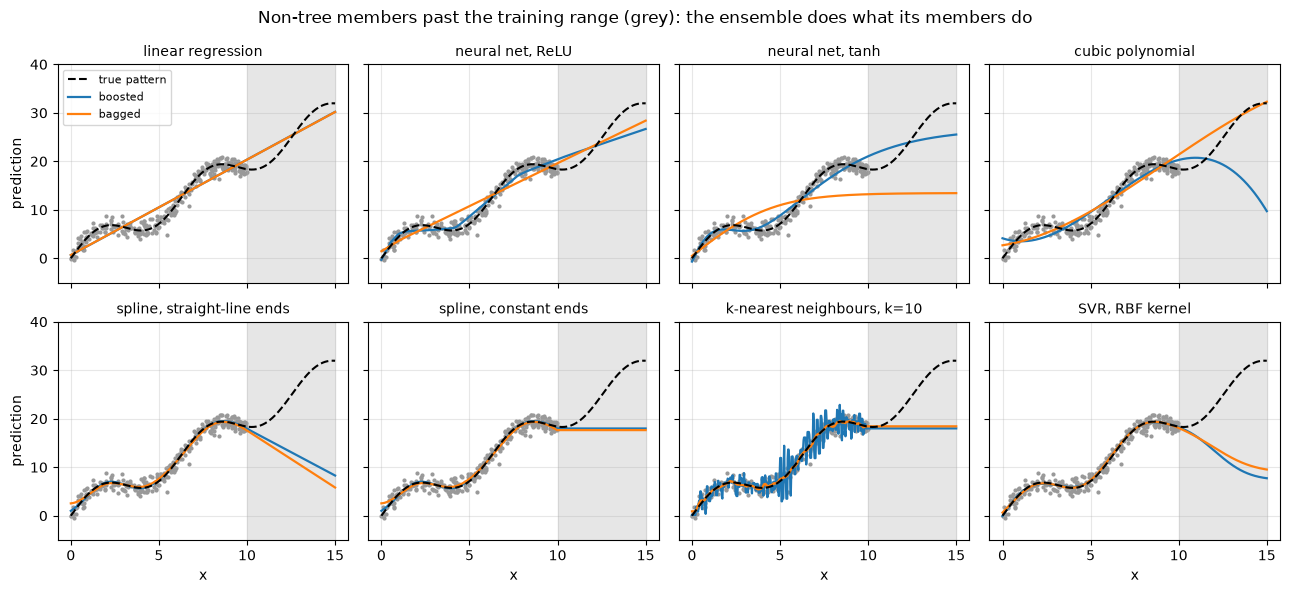

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, MEMBERS):
    draw_background(ax)
    ax.plot(x_plot, boosted[name](X_plot), color="tab:blue", lw=1.6, label="boosted", zorder=3)
    ax.plot(x_plot, bagged[name](X_plot), color="tab:orange", lw=1.6, label="bagged", zorder=3)
    ax.set_title(name, fontsize=10)
    if ax not in axes[-1]:
        ax.set_xlabel("")
axes[0, 0].set_ylim(-5, 40)
axes[0, 0].legend(loc="upper left", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("prediction")
fig.suptitle("Non-tree members past the training range (grey): the ensemble does what its members do")
plt.tight_layout(); plt.show()

> **How to read this**
> * **The members decide.** Flat members give flat ensembles (spline with constant ends, k-NN: 17.6–18.4).
>   Members that continue their edge slope go *down*, because the wave slopes down at $x = 10$ (spline with
>   straight-line ends: 8.3 boosted, 5.8 bagged). SVR falls back towards its intercept (7.7, 9.5). Boosted and
>   bagged versions behave the same way past the edge.
> * **Read the `inside` column before trusting a good extrapolation.** Bagged ReLU nets reach 28.4 at $x = 15$,
>   but their fit inside the range (2.06) is no better than one straight line (1.99): averaging 50 small nets
>   gave an almost straight curve that never learned the wave. Boosted ReLU nets follow the wave (0.97) and
>   still rise outside (26.7). Bagged tanh nets do badly on both (3.71 inside, flat at 13.4 outside).
> * **The best fits inside extrapolate worst.** SVR and the splines fit the range almost perfectly (0.16–0.47)
>   and miss by 14–16 RMSE outside it. How well a model fits the data says nothing about what it does beyond it.
> * **The boosted and bagged cubic disagree by 22.6** (9.7 vs 32.3) on the same data. The check below shows
>   why: bagging keeps the cubic's small ridge penalty, boosting removes it.
> * **Boosting a strong member chases noise.** Boosted k-NN is jagged inside the range (1.86 against 0.27 when
>   bagged): 100 rounds of k-NN on the residuals fit the noise. Boosting is built for weak members; the check
>   below measures which members left it anything to do.

### Part B, check · Did boosting and bagging do anything here?

The table above compares *boosted* with *bagged*, but never with the member **on its own**. That matters,
because boosting has two known traps ([README section 13.2](../README.md#132-an-ensemble-is-not-automatically-better-applies-beyond-voting-disadvantage-6); `04-adaboost/` §8.3):

* **The member cannot capture the leftover error.** If adding two members gives another member of the same
  kind (two straight lines give a straight line; two cubics a cubic; two splines on the same knots a spline),
  boosting can only end at that kind's own best fit — and any ridge penalty inside the member gets undone, as
  part A's continuation showed for `Ridge`.
* **The member is too strong.** If one member already explains everything except the noise, later rounds have
  only noise left to fit. AdaBoost stops after one round in that case; gradient boosting keeps going and fits
  the noise.

Two measurements test this:

1. each member **alone**, next to its boosted and bagged versions;
2. how much of the data **one member leaves unexplained** — the table's *unexplained by one member* column:
   * fit one member, once, on its own, to the training data;
   * the training targets' **variation** is how far they spread around their average, $\sum (y - \bar y)^2$;
   * what the member **leaves unexplained** is how far they still spread around its predictions, $\sum (y - \hat y)^2$;
   * the column is the second divided by the first — $1 - R^2$ on the training data. 0 % means the member
     reproduces the training targets exactly; 100 % means it does no better than predicting their average;
   * compare it with the share of the variation that is **pure noise** (printed first). If one member already
     leaves only about that much, boosting's later rounds have nothing but noise to fit (trap 2). If it leaves much
     more, real error is left — but boosting can use it only if adding members gives something more flexible than
     one member, which is not the case for trap-1 members.

The cubic and the splines carry a ridge penalty (`Ridge(1.0)`), so they are also fitted without it, to see where
boosting drifts.

In [10]:
UNPENALIZED = {   # the same members without the ridge penalty
    "cubic polynomial": make_pipeline(PolynomialFeatures(3), StandardScaler(), LinearRegression()),
    "spline, straight-line ends": make_pipeline(SplineTransformer(n_knots=6, extrapolation="linear"), LinearRegression()),
    "spline, constant ends": make_pipeline(SplineTransformer(n_knots=6, extrapolation="constant"), LinearRegression()),
}
alone = {name: clone(member).fit(X_tr, y_tr).predict for name, member in MEMBERS.items()}


def share_left(predict):
    """Share of the training targets' variation that a fitted model leaves unexplained (1 - R² on training data)."""
    return np.sum((y_tr - predict(X_tr)) ** 2) / np.sum((y_tr - y_tr.mean()) ** 2)


noise_share = N_TRAIN * NOISE_SD ** 2 / np.sum((y_tr - y_tr.mean()) ** 2)
print(f"pure noise is about {noise_share:.1%} of the training targets' variation\n")
print(f"{'member':<28} {'unexplained':>13} |{'at x = 15':^22}|{'RMSE inside':^22}")
print(f"{'':<28} {'by one member':>13} |" + f"{'alone':>7}{'boosted':>8}{'bagged':>7}|" * 2)
for name in MEMBERS:
    (_, a15, _, a_in), (_, b15, _, b_in), (_, g15, _, g_in) = (score(p[name]) for p in (alone, boosted, bagged))
    print(f"{name:<28} {share_left(alone[name]):13.1%} |{a15:7.1f}{b15:8.1f}{g15:7.1f}|{a_in:7.2f}{b_in:8.2f}{g_in:7.2f}|")

print("\nthe same members without the ridge penalty, alone:")
for name, member in UNPENALIZED.items():
    _, at_15, _, rmse_inside = score(clone(member).fit(X_tr, y_tr).predict)
    print(f"{name:<28} at x = 15 {at_15:6.1f}   RMSE inside {rmse_inside:5.2f}")

pure noise is about 2.6% of the training targets' variation

member                         unexplained |      at x = 15       |     RMSE inside      
                             by one member |  alone boosted bagged|  alone boosted bagged|
linear regression                    12.0% |   30.2    30.2   30.2|   1.99    1.99   1.99|
neural net, ReLU                     12.1% |   29.3    26.7   28.4|   2.00    0.97   2.06|
neural net, tanh                     39.3% |   13.8    25.5   13.4|   3.58    1.19   3.71|
cubic polynomial                     10.0% |   32.2     9.7   32.3|   1.77    1.74   1.77|
spline, straight-line ends            2.8% |    5.7     8.3    5.8|   0.46    0.21   0.47|


spline, constant ends                 2.8% |   17.6    18.0   17.6|   0.46    0.21   0.47|
k-nearest neighbours, k=10            2.2% |   18.4    18.0   18.4|   0.30    1.86   0.27|


SVR, RBF kernel                       2.4% |    9.4     7.7    9.5|   0.16    0.16   0.18|

the same members without the ridge penalty, alone:
cubic polynomial             at x = 15    6.5   RMSE inside  1.75
spline, straight-line ends   at x = 15   14.6   RMSE inside  0.14
spline, constant ends        at x = 15   18.3   RMSE inside  0.14


> **How to read this**
> * **Pure noise is 2.6 % of the variation** — no model can explain that part.
> * **Trap 1, the member cannot capture the leftover error.** Linear regression is identical alone, boosted and
>   bagged (30.2). The cubic and the straight-ended spline show the penalty effect: bagging leaves them where
>   they are alone (32.3 vs 32.2; 5.8 vs 5.7), while boosting drifts towards the *unpenalized* fit (cubic 9.7,
>   heading for 6.5; spline 8.3, heading for 14.6). So the 22.6 gap between the boosted and bagged cubic is the
>   ridge penalty being undone, magnified by how sensitive a cubic is far from its data. The lucky part is only
>   that the penalized cubic happens to land near the truth (32.2 vs 32.0).
> * **Trap 2, the member is too strong.** One spline, k-NN or SVR already leaves only 2.2–2.8 % — about the
>   noise level — so later rounds have nothing real to fit. Boosted SVR fits exactly as well as SVR alone (0.16);
>   boosted k-NN fits *worse* (0.30 → 1.86): a k-NN prediction is an average of neighbours, not a least-squares
>   fit, so extra rounds are not guaranteed to reduce the error. (The splines' inside fit improves under
>   boosting, 0.46 → 0.21, only because boosting removes their penalty — trap 1 again.)
> * **Only the neural nets left boosting real work.** One net leaves 12.1 % (ReLU) and 39.3 % (tanh), far above
>   the noise, and boosting cuts the inside error from 2.00 to 0.97 and from 3.58 to 1.19.
> * **Bagging changed little for any member**: bagged and alone differ by at most 0.9 at $x = 15$ (ReLU) and
>   0.13 in inside RMSE (tanh). These members change little from one bootstrap sample to the next.
> * So part B's table mostly compares **kinds of member**, not boosting with bagging — which is exactly why
>   "extrapolation is a property of the members" holds there.

### Part B, continued · Boosting and bagging linear models, with and without penalties

In the first panel above, boosted and bagged linear regression both look like one linear regression. Here we
put each plain linear model next to its boosted version (100 rounds, learning rate 0.1, the same
`gradient_boost` loop) and its bagged version (50 bootstrap copies) — same data, same settings as the rest of
part B — for no penalty, L2 (ridge) and L1 (lasso), with the penalties of part A's continuation.

In [11]:
LINEAR_MEMBERS = {
    "linear regression": LinearRegression(),
    "ridge (L2)": Ridge(alpha=LAMBDA * N),
    "lasso (L1)": Lasso(alpha=ALPHA),
}
linear_versions = {   # member -> {"single" | "boosted" | "bagged": predict}
    name: {
        "single": clone(member).fit(X_tr, y_tr).predict,
        "boosted": gradient_boost(member, X_tr, y_tr, rounds=100, learning_rate=0.1),
        "bagged": BaggingRegressor(estimator=member, n_estimators=50, random_state=SEED).fit(X_tr, y_tr).predict,
    }
    for name, member in LINEAR_MEMBERS.items()
}

print(f"{'member':<18} {'version':<8} {'slope':>6} {'intercept':>10} {'at 15':>6} {'RMSE test':>10} {'RMSE inside':>12}")
for name, versions in linear_versions.items():
    for version, predict in versions.items():
        slope, intercept = slope_and_intercept(predict)
        _, at_15, rmse_test, rmse_inside = score(predict)
        print(f"{name:<18} {version:<8} {slope:6.3f} {intercept:10.3f} {at_15:6.1f} {rmse_test:10.1f} {rmse_inside:12.2f}")

member             version   slope  intercept  at 15  RMSE test  RMSE inside
linear regression  single    1.970      0.655   30.2        2.4         1.99
linear regression  boosted   1.970      0.655   30.2        2.4         1.99
linear regression  bagged    1.966      0.677   30.2        2.4         1.99
ridge (L2)         single    1.770      1.735   28.3        2.8         2.06
ridge (L2)         boosted   1.970      0.656   30.2        2.4         1.99
ridge (L2)         bagged    1.766      1.763   28.2        2.9         2.06
lasso (L1)         single    1.857      1.265   29.1        2.6         2.01


lasso (L1)         boosted   1.855      1.274   29.1        2.6         2.01
lasso (L1)         bagged    1.853      1.292   29.1        2.6         2.01


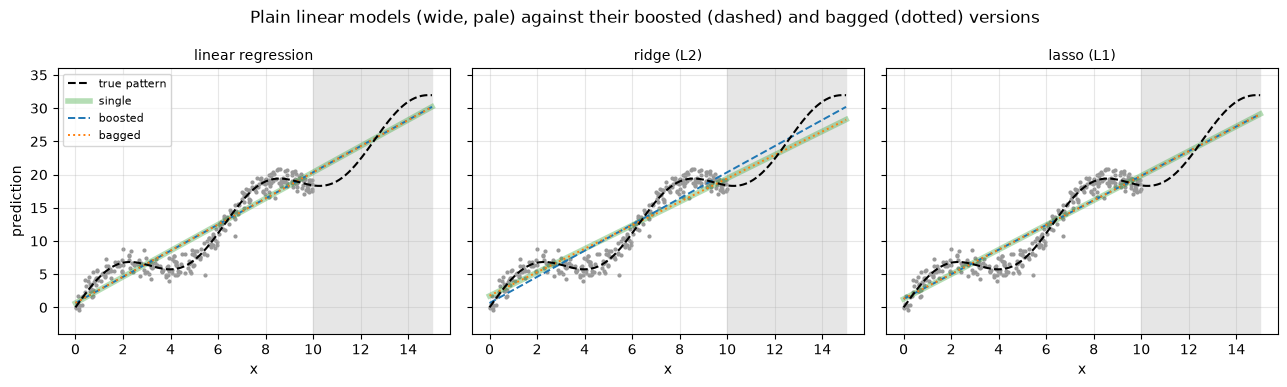

In [12]:
STYLES = {"single": dict(color="tab:green", lw=4, alpha=0.35), "boosted": dict(color="tab:blue", lw=1.4, ls="--"),
          "bagged": dict(color="tab:orange", lw=1.4, ls=":")}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (name, versions) in zip(axes, linear_versions.items()):
    draw_background(ax)
    for version, predict in versions.items():
        ax.plot(x_plot, predict(X_plot), label=version, zorder=3, **STYLES[version])
    ax.set_title(name, fontsize=10)
axes[0].set(ylabel="prediction", ylim=(-4, 36))
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Plain linear models (wide, pale) against their boosted (dashed) and bagged (dotted) versions")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Boosting a linear regression gives the same linear regression** (slope 1.970, intercept 0.655 in both
>   rows). The first round already captures every straight-line pattern; the residuals left over have no
>   straight-line pattern for later rounds to pick up.
> * **Boosting undoes ridge's penalty but keeps lasso's.** Boosted ridge ends at plain linear regression (slope
>   1.970, not 1.770); boosted lasso stays lasso (1.855 against 1.857). Ridge shrinks every fit by a
>   *fraction*, so each round still captures part of what the previous rounds left, and 100 rounds add up to
>   the unshrunk fit. Lasso subtracts a *fixed amount* from the slope it would fit; once the leftover slope is
>   smaller than that amount, lasso fits nothing and the rounds stop changing the sum.
> * **Bagging changes nothing that matters** (slopes within 0.004 of the single model): a linear model barely
>   changes from one bootstrap sample to the next, so there is nothing to average away — the "copies" case of
>   README section 13.2.
> * Hence part B's first panel: past the edge, an ensemble of linear models is a linear model.

---
## Part C · Are the neural-net ensembles reliable?

**Goal:** part B used one random seed. A network's starting weights are random, so we repeat the neural-net
rows for five seeds: one net on its own, 20 nets bagged, and 30 nets boosted (learning rate 0.3). If the
prediction at $x = 15$ barely moves between seeds, the extrapolation is a property of the method; if it jumps
around, it is luck.

In [13]:
N_SEEDS = 5
at_15_by_seed = {}                          # (activation, kind) -> prediction at x = 15 for each seed
relu_curves = {"bagged": [], "boosted": []}   # full curves, for the plot below

for activation in ("relu", "tanh"):
    for kind in ("single", "bagged", "boosted"):
        for seed in range(N_SEEDS):
            net = small_net(activation, seed, max_iter=1000)
            if kind == "single":
                predict = net.fit(X_tr, y_tr).predict
            elif kind == "bagged":
                predict = BaggingRegressor(estimator=net, n_estimators=20, random_state=seed).fit(X_tr, y_tr).predict
            else:
                predict = gradient_boost(net, X_tr, y_tr, rounds=30, learning_rate=0.3)
            at_15_by_seed.setdefault((activation, kind), []).append(predict(X_POINTS)[1])
            if activation == "relu" and kind in relu_curves:
                relu_curves[kind].append(predict(X_plot))

print(f"prediction at x = 15 (truth {true_pattern(15):.1f}) for seeds 0-{N_SEEDS - 1}")
for (activation, kind), values in at_15_by_seed.items():
    print(f"{activation:<5} {kind:<8} " + " ".join(f"{v:6.1f}" for v in values)
          + f"   spread {max(values) - min(values):4.1f}")

prediction at x = 15 (truth 32.0) for seeds 0-4
relu  single     29.5   29.6   29.7   29.9   29.6   spread  0.4
relu  bagged     28.2   28.4   28.2   28.1   27.9   spread  0.5
relu  boosted    25.1   34.6   34.6   32.2   30.6   spread  9.5
tanh  single     18.3   17.8   18.1   18.4   17.2   spread  1.2
tanh  bagged     17.2   17.6   17.3   16.9   16.7   spread  0.9
tanh  boosted    23.5   23.6   24.2   25.1   23.8   spread  1.6


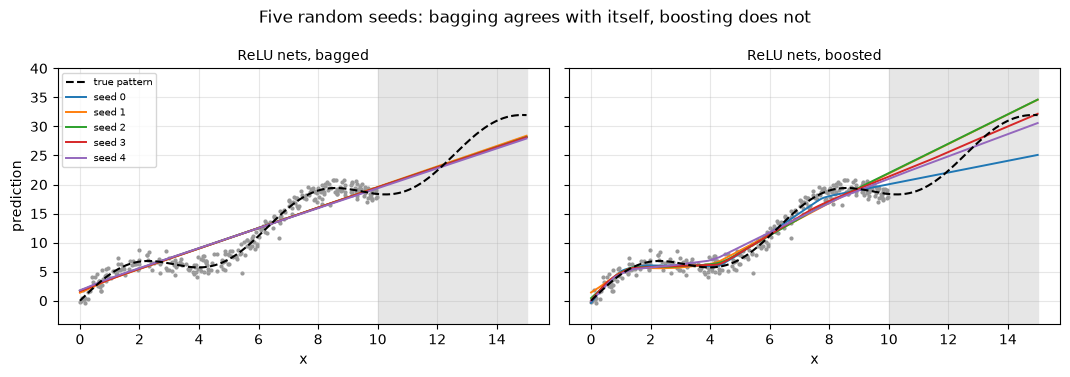

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.8), sharey=True)
for ax, (kind, curves) in zip(axes, relu_curves.items()):
    draw_background(ax)
    for seed, curve in enumerate(curves):
        ax.plot(x_plot, curve, lw=1.4, label=f"seed {seed}", zorder=3)
    ax.set_title(f"ReLU nets, {kind}", fontsize=10)
axes[0].set(ylabel="prediction", ylim=(-4, 40))
axes[0].legend(loc="upper left", fontsize=7)
fig.suptitle("Five random seeds: bagging agrees with itself, boosting does not")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Single and bagged ReLU nets agree with themselves** across seeds (spread 0.4 and 0.5 at $x = 15$). They
>   land near 28–30, close to one linear regression's 30.2 — consistent with part B: these small nets end up
>   close to a straight line, and straight lines from different seeds agree.
> * **Boosted ReLU nets do not** (25.1 to 34.6, spread 9.5). The right panel shows why: the five sums agree
>   inside the range and fan out past it. After the first rounds each net fits leftover error that is mostly
>   noise, and the slopes those nets have past the edge add up differently for every seed.
> * **tanh nets level off in every version,** below the truth (16.7–25.1), because every tanh unit saturates
>   far from the data.

---
## Part D · Does the answer depend on the curve?

**Goal:** the curve so far, $2x + 3\sin x$, keeps rising. A straight line suits it unusually well, which may be
why linear members (and nearly straight bagged nets) looked good past the edge. Here the same experiment runs
on a curve with **no trend that keeps returning to zero**: $y = 3\sin x$, which crosses $y = 0$ three times
inside the training range and once more in the test range. Same noise, same 300 training $x$ values, same
train and test ranges, same members and settings as parts A and B.

Two references:

* **predicting 0 everywhere** — on a wave around zero, any model that is worth using past the edge should beat
  this;
* **a model that knows the shape** — linear regression on $\sin x$ and $\cos x$ at the true frequency. It is not
  a fair competitor (it was told the answer's form); it shows what extrapolation needs.

The *unexplained by one member* column is the measure defined in part B's check: $1 - R^2$ of one member on
the training data, to be compared with the share of the variation that is pure noise (printed below).

In [15]:
def wave(x):
    return 3 * np.sin(x)


rng_wave = np.random.default_rng(SEED)
xw_tr = rng_wave.uniform(X_MIN, X_EDGE, N_TRAIN)        # the same draws as part A's data
yw_tr = wave(xw_tr) + rng_wave.normal(0, NOISE_SD, N_TRAIN)
Xw_tr = xw_tr[:, None]


def score_wave(predict):
    """Prediction at x = 15, RMSE on the test range, RMSE against the wave inside the training range."""
    at_15 = predict(np.array([[15.0]]))[0]
    rmse_test = np.sqrt(np.mean((predict(X_te) - wave(x_te)) ** 2))
    rmse_inside = np.sqrt(np.mean((predict(X_in) - wave(x_in)) ** 2))
    return at_15, rmse_test, rmse_inside


def share_left_wave(predict):
    """Part B's check measure on the wave data: 1 - R² of a fitted model on the training data."""
    return np.sum((yw_tr - predict(Xw_tr)) ** 2) / np.sum((yw_tr - yw_tr.mean()) ** 2)


print(f"truth at x = 15: {wave(15):.1f}")
print(f"pure noise is about {N_TRAIN * NOISE_SD ** 2 / np.sum((yw_tr - yw_tr.mean()) ** 2):.1%} of the variation")
print(f"test RMSE of predicting 0 everywhere: {np.sqrt(np.mean(wave(x_te) ** 2)):.2f}")

truth at x = 15: 2.0
pure noise is about 21.3% of the variation
test RMSE of predicting 0 everywhere: 2.31


In [16]:
WAVE_MEMBERS = {
    "linear regression": LinearRegression(),
    "ridge (L2)": Ridge(alpha=LAMBDA * N),
    "lasso (L1)": Lasso(alpha=ALPHA),
    **{name: member for name, member in MEMBERS.items() if name != "linear regression"},
    "knows the shape: sin, cos": make_pipeline(
        FunctionTransformer(lambda X: np.hstack([np.sin(X), np.cos(X)])), LinearRegression()),
}
wave_versions = {
    name: {
        "alone": clone(member).fit(Xw_tr, yw_tr).predict,
        "boosted": gradient_boost(member, Xw_tr, yw_tr, rounds=100, learning_rate=0.1),
        "bagged": BaggingRegressor(estimator=member, n_estimators=50, random_state=SEED).fit(Xw_tr, yw_tr).predict,
    }
    for name, member in WAVE_MEMBERS.items()
}
wave_trees = {
    "random forest": RandomForestRegressor(n_estimators=300, random_state=SEED).fit(Xw_tr, yw_tr).predict,
    "gradient boosting, depth 3": GradientBoostingRegressor(n_estimators=300, max_depth=3, random_state=SEED)
    .fit(Xw_tr, yw_tr).predict,
    "xgboost, depth 6": xgb.XGBRegressor(n_estimators=300, max_depth=6).fit(Xw_tr, yw_tr).predict,
}

print(f"{'tree ensemble':<28} {'at 15':>6} {'test':>6} {'inside':>7}")
for name, predict in wave_trees.items():
    print(f"{name:<28} {{:6.1f}} {{:6.2f}} {{:7.2f}}".format(*score_wave(predict)))

print(f"\n{'member':<28} {'unexplained':>13} |{'at x = 15':^21}|{'RMSE test':^21}|{'RMSE inside':^21}")
print(f"{'':<28} {'by one member':>13} |" + f"{'alone':>7}{'boost':>7}{'bag':>7}|" * 3)
for name, versions in wave_versions.items():
    scores = [score_wave(versions[v]) for v in ("alone", "boosted", "bagged")]
    cells = "|".join("".join(f"{s[k]:7.{1 if k == 0 else 2}f}" for s in scores) for k in range(3))
    print(f"{name:<28} {share_left_wave(versions['alone']):13.1%} |{cells}|")

tree ensemble                 at 15   test  inside
random forest                  -1.8   2.88    0.66
gradient boosting, depth 3     -2.0   3.05    0.64
xgboost, depth 6               -1.4   2.70    0.95

member                         unexplained |      at x = 15      |      RMSE test      |     RMSE inside     
                             by one member |  alone  boost    bag|  alone  boost    bag|  alone  boost    bag|
linear regression                    99.8% |    0.2    0.2    0.2|   2.37   2.37   2.38|   1.99   1.99   1.99|
ridge (L2)                           99.8% |    0.2    0.2    0.2|   2.37   2.37   2.38|   1.99   1.99   1.99|
lasso (L1)                          100.0% |    0.5    0.5    0.5|   2.37   2.37   2.37|   2.00   2.00   2.00|
neural net, ReLU                     76.7% |    1.3   -2.0    0.8|   2.43   3.07   2.36|   1.69   0.98   1.96|
neural net, tanh                     74.6% |    1.6    1.8    0.6|   2.55   2.94   2.34|   1.66   1.32   1.92|
cubic polynomial   

spline, straight-line ends           21.0% |   -8.9  -12.8   -8.8|   6.67   9.01   6.64|   0.28   0.13   0.28|
spline, constant ends                21.0% |   -1.1   -1.5   -1.0|   2.52   2.73   2.52|   0.28   0.13   0.28|
k-nearest neighbours, k=10           18.1% |   -1.4   -1.9   -1.3|   2.66   2.99   2.64|   0.29   1.86   0.27|


SVR, RBF kernel                      20.2% |   -1.5   -3.3   -1.4|   3.27   5.11   3.17|   0.15   0.16   0.15|
knows the shape: sin, cos            19.9% |    1.9    1.9    1.9|   0.09   0.09   0.09|   0.07   0.07   0.07|


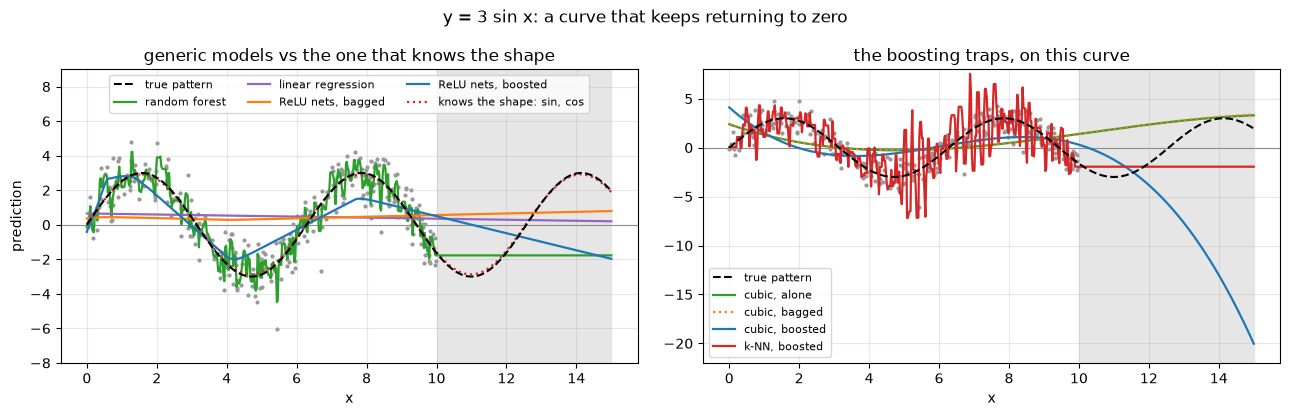

In [17]:
xw_plot_truth = wave(x_plot)


def draw_wave_background(ax):
    ax.axvspan(X_EDGE, X_FAR, color="0.9", zorder=0)
    ax.axhline(0, color="0.5", lw=0.8, zorder=1)
    ax.scatter(xw_tr, yw_tr, s=4, color="0.6", zorder=1)
    ax.plot(x_plot, xw_plot_truth, "k--", lw=1.5, label="true pattern", zorder=4)
    ax.set_xlabel("x")


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
left_lines = {"random forest": (wave_trees["random forest"], "tab:green", "-"),
              "linear regression": (wave_versions["linear regression"]["alone"], "tab:purple", "-"),
              "ReLU nets, bagged": (wave_versions["neural net, ReLU"]["bagged"], "tab:orange", "-"),
              "ReLU nets, boosted": (wave_versions["neural net, ReLU"]["boosted"], "tab:blue", "-"),
              "knows the shape: sin, cos": (wave_versions["knows the shape: sin, cos"]["alone"], "tab:red", ":")}
right_lines = {"cubic, alone": (wave_versions["cubic polynomial"]["alone"], "tab:green", "-"),
               "cubic, bagged": (wave_versions["cubic polynomial"]["bagged"], "tab:orange", ":"),
               "cubic, boosted": (wave_versions["cubic polynomial"]["boosted"], "tab:blue", "-"),
               "k-NN, boosted": (wave_versions["k-nearest neighbours, k=10"]["boosted"], "tab:red", "-")}
for ax, lines, title, ylim, where in [(axes[0], left_lines, "generic models vs the one that knows the shape", (-8, 9), "upper center"),
                                      (axes[1], right_lines, "the boosting traps, on this curve", (-22, 8), "lower left")]:
    draw_wave_background(ax)
    for label, (predict, color, style) in lines.items():
        ax.plot(x_plot, predict(X_plot), color=color, ls=style, lw=1.6, label=label, zorder=3)
    ax.set(title=title, ylim=ylim)
    ax.legend(loc=where, fontsize=8, ncol=3 if where == "upper center" else 1)
axes[0].set_ylabel("prediction")
fig.suptitle("y = 3 sin x: a curve that keeps returning to zero")
plt.tight_layout(); plt.show()

> **How to read this**
> * **What came from the curve.** The linear models now leave 99.8–100 % of the variation unexplained and
>   predict roughly the average everywhere (0.2–0.5 at $x = 15$); their test RMSE (2.37) is no better than
>   predicting 0 (2.31). Their errors are *exactly* the ones they had on the first curve (2.37 test, 1.99
>   inside): a straight line fitted to $2x + 3\sin x$ is $2x$ plus the line it would fit to the wave alone. On the
>   first curve they never followed the wave either; they got the trend for free.
> * **No generic model beats predicting 0 past the edge.** The closest are the bagged nets (2.34–2.36) — by being
>   nearly flat lines (inside 1.92–1.96, they barely follow the wave) — and the spline with constant ends (2.52).
>   Tree ensembles go flat at their last leaf again (−1.4 to −2.0; test 2.70–3.05).
> * **Only the model that knows the shape extrapolates** (0.09 test, 0.07 inside). It works because it was
>   given the truth's form; on the first curve, without a straight-line term, that same form would be wrong.
> * **What is built into the methods — unchanged on this curve.** Trap 1: linear, ridge and lasso are identical
>   alone, boosted and bagged; boosting removes the cubic's ridge penalty and it swings to −20.0 at $x = 15$
>   (bagged stays with the cubic alone, 3.4 vs 3.3). Trap 2: the splines, k-NN and SVR leave 18.1–21.0 %, about
>   the 21.3 % that is noise, so boosting fits noise: boosted k-NN gets worse inside (0.29 → 1.86), boosted SVR
>   worse outside (3.27 → 5.11).
> * **The nets are again the only members boosting helps inside the range** (they leave 74.6–76.7 %): ReLU
>   1.69 → 0.98, tanh 1.66 → 1.32. Past the edge it hurts them here (2.43 → 3.07, 2.55 → 2.94).

---
## What this shows

* **Extrapolation is a property of the members, not of the ensemble.** Boosting adds the members'
  predictions and bagging averages them, so past the training range the ensemble does whatever its members do
  there. Flat members give a flat ensemble; members that continue the edge slope give an ensemble that
  continues the edge slope (parts A and B).
* **Bagged small ReLU networks extrapolate reliably here — but largely because they are nearly straight lines.**
  Their fit inside the range is no better than one linear regression (2.06 against 1.99), and five seeds agree
  (spread 0.5). Averaging separately trained networks is common practice, often called a *deep ensemble*.
* **Boosted small ReLU networks fit the wave but extrapolate unreliably** (spread 9.5 across seeds). Boosting is
  designed for weak members; a network is already strong, which is one reason networks are rarely boosted.
* **tanh networks go flat like trees,** because every tanh unit levels off far from the data.
* **Linear members collapse into one linear model.** xgboost's `gblinear` is exactly `LinearRegression`,
  `Ridge` or `Lasso` (largest gap 6.3e-06); boosting a linear regression returns it unchanged; boosting ridge
  undoes its penalty (slope 1.770 → 1.970) while boosting lasso keeps it; bagging changes nothing.
* **Continuing the edge slope is not the same as continuing the trend.** The spline that continued its edge
  slope and LightGBM's linear leaves both went downhill while the truth went up, and a cubic's prediction at
  $x = 15$ moved from 32.2 to 9.7 just because boosting removed its small ridge penalty.
* **Most non-tree members left boosting nothing to do.** Linear models, cubics and splines can only add up to
  one member of their own kind; splines, k-NN and SVR already explain everything but the noise after one fit.
  Only the neural nets left real error for later rounds (part B's check).
* **Only a model whose shape matches the truth extrapolates** (part D). On a curve that keeps returning to
  zero, no generic model — boosted, bagged or alone — beats predicting 0 past the edge (2.31); the linear
  models' earlier success came from the trend in the first curve. A model given the true shape reaches 0.09.
* **A good fit inside the range says nothing about outside it.** The best fits inside (SVR, splines) were among
  the worst outside.
* **The reliable fix is to choose the shape on purpose:** model the trend explicitly (a linear or domain model)
  and let the ensemble fit what is left inside the range — `init=LinearRegression()` or xgboost's `base_margin`
  in part A fit well inside (0.65, 0.95) *and* keep the trend outside (27.8, 28.4).
* **Wording of disadvantage 4.** "Predictions stay within the range of training targets" is true for bagging
  and random forests, which average leaf values. Boosting *adds* leaf values and can overshoot the training
  targets. What holds for every tree ensemble is that predictions go **flat beyond the edge of the training
  inputs**.